In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("/content/Social_Network_Ads.csv")


In [3]:
from sklearn.cluster import DBSCAN
from sklearn.preprocessing import StandardScaler

Feature matrix shape: (400, 2)
Unique clusters found: [-1  0  1  2  3  4]
Number of points per cluster:
Noise/Outliers: 23
Cluster 0: 290
Cluster 1: 52
Cluster 2: 9
Cluster 3: 11
Cluster 4: 15


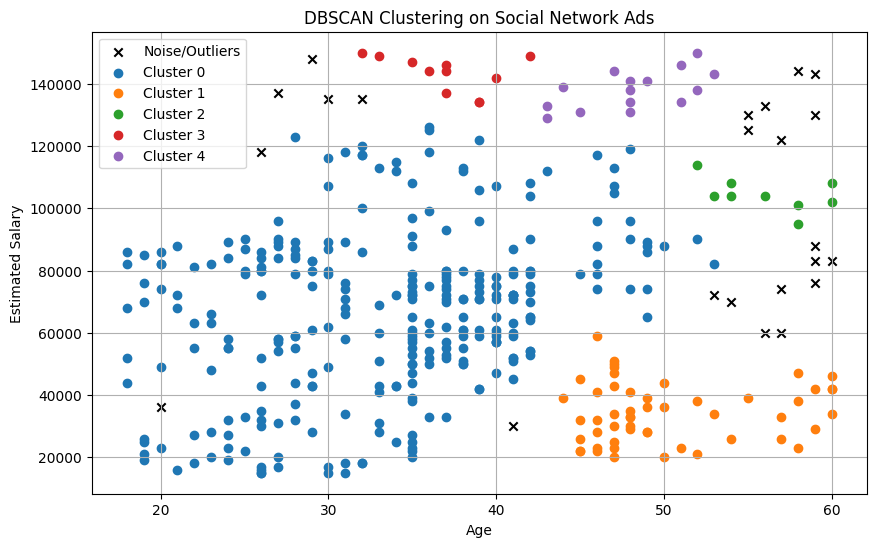

In [4]:

# Step 1: Select Features (Age and EstimatedSalary)
X = df[['Age', 'EstimatedSalary']].values
print(f"Feature matrix shape: {X.shape}")

# Step 2: Feature Scaling
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Step 3: Apply DBSCAN
# We start with default/reasonable hyperparameters and fit the model
model = DBSCAN(eps=0.3, min_samples=5)
yhat = model.fit_predict(X_scaled)

# Step 4: Identify unique clusters
clusters = np.unique(yhat)
print(f"Unique clusters found: {clusters}")

# Step 5: Display count of points in each cluster
print("Number of points per cluster:")
for cluster in clusters:
    count = np.sum(yhat == cluster)
    if cluster == -1:
        print(f"Noise/Outliers: {count}")
    else:
        print(f"Cluster {cluster}: {count}")

# Step 6: Visualize the DBSCAN clusters
plt.figure(figsize=(10, 6))
for cluster in clusters:
    row_ix = np.where(yhat == cluster)
    if cluster == -1:
        plt.scatter(X[row_ix, 0], X[row_ix, 1], label='Noise/Outliers', color='black', marker='x')
    else:
        plt.scatter(X[row_ix, 0], X[row_ix, 1], label=f'Cluster {cluster}')

plt.title('DBSCAN Clustering on Social Network Ads')
plt.xlabel('Age')
plt.ylabel('Estimated Salary')
plt.legend()
plt.grid(True)
plt.show()

Aim:
To implement DBSCAN (Density-Based Spatial Clustering of Applications with Noise) Clustering in Python.

Objective:
To perform density-based clustering on a dataset, identify clusters of arbitrary shapes, and separate noise/outliers from valid data clusters without specifying the number of clusters in advance.

Theory:
DBSCAN (Density-Based Spatial Clustering of Applications with Noise) is an unsupervised density-based clustering algorithm. Unlike partitioning algorithms such as K-Means, which assume spherical clusters and require the user to predefine the number of clusters (k), DBSCAN groups together data points that are closely packed in high-density regions and marks points that lie alone in low-density regions as outliers (noise).

DBSCAN relies on two primary parameters:
1. Epsilon (eps): The maximum radius of the neighborhood around a data point.
2. Minimum Points (min_samples / MinPts): The minimum number of data points required within the epsilon-neighborhood to form a dense region (including the point itself).

Based on these parameters, every point in the dataset is classified into one of three categories:
- Core Point: A point that has at least min_samples points within its epsilon-radius.
- Border Point: A point that has fewer than min_samples points within its epsilon-radius, but lies within the epsilon-neighborhood of a Core Point.
- Noise Point (Outlier): Any point that is neither a Core Point nor a Border Point (labeled as -1 in scikit-learn).

Algorithm:
1. Select an unvisited data point p from the dataset.
2. Find all neighbor points within distance eps from p.
3. Check the density condition:
   - If the number of neighbors is less than min_samples, temporarily mark p as Noise (it may later become a Border Point if found in the neighborhood of another Core Point).
   - If the number of neighbors is greater than or equal to min_samples, mark p as a Core Point and start a new cluster C.
4. Add p and all its eps-neighbors to cluster C.
5. Recursively examine each neighbor q in cluster C: if q is also a Core Point, add all of q's unvisited eps-neighbors to cluster C.
6. Repeat Steps 1 to 5 until all points in the dataset have been visited.

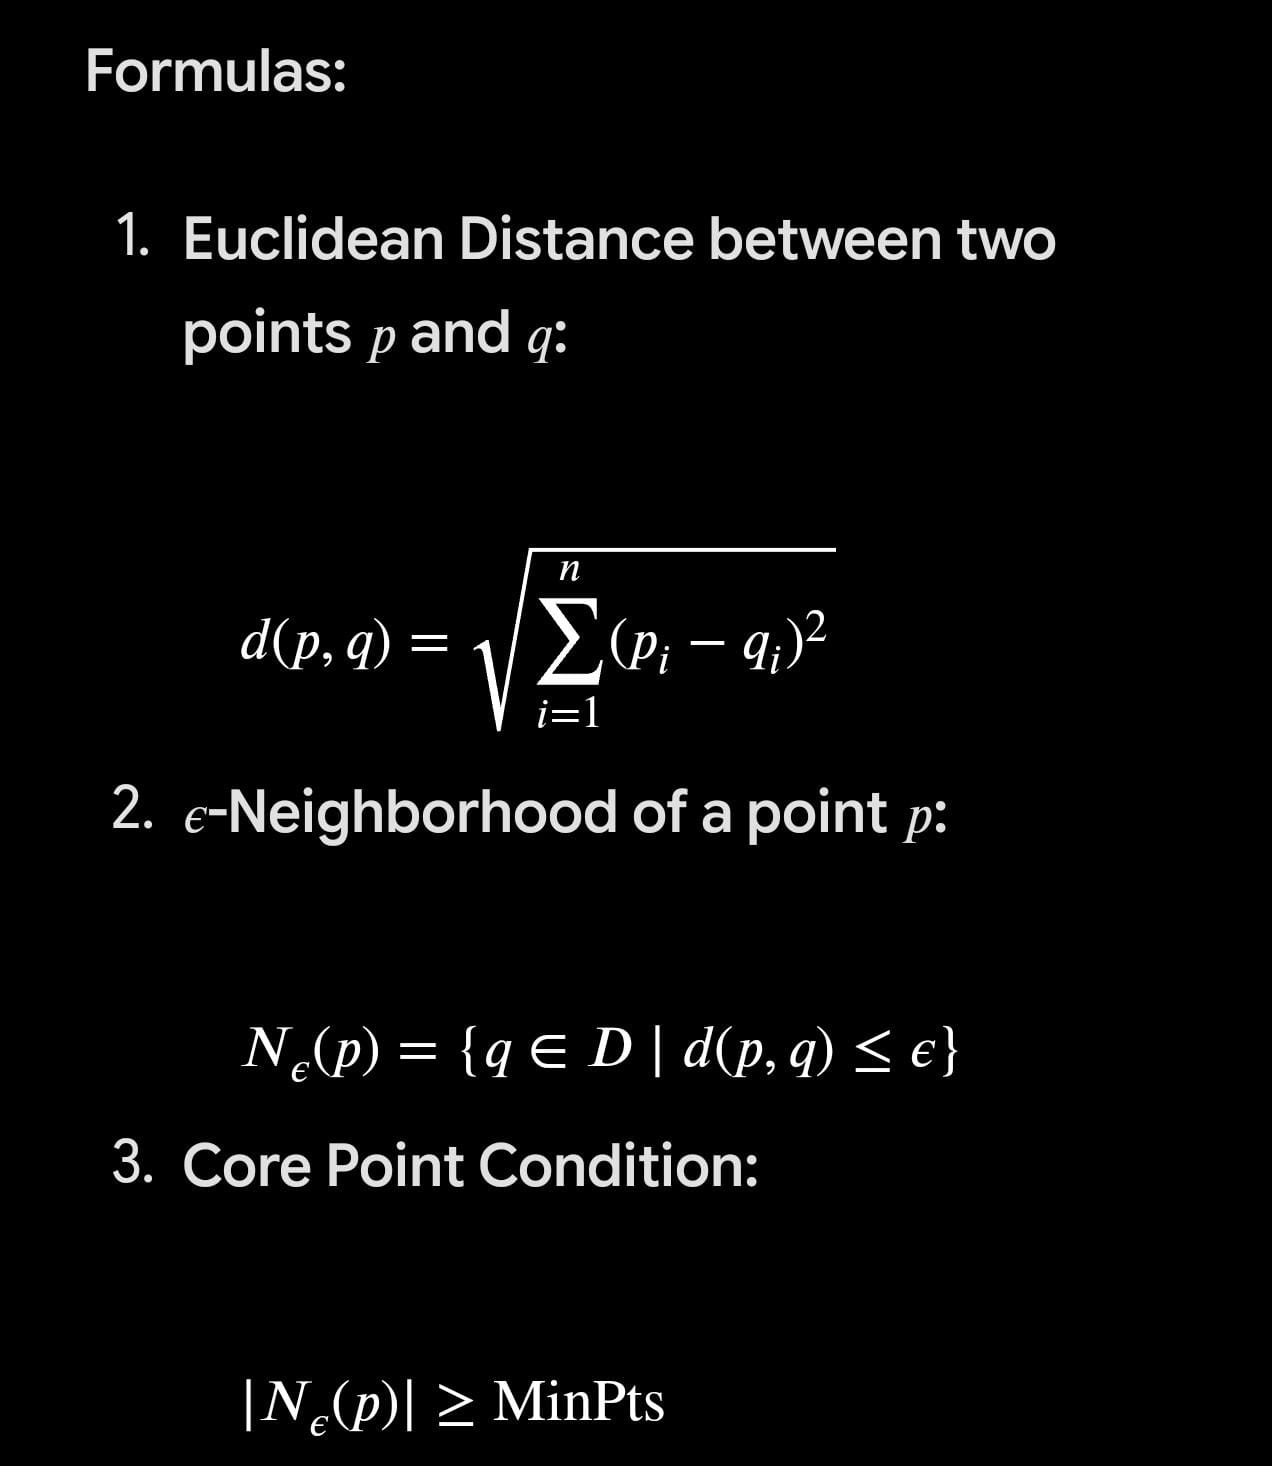

Conclusion:
Hence, we have successfully studied and implemented DBSCAN clustering in the Python programming language to group dense regions and detect outliers.